# 02 · Exploratory analysis

Scope: only what affects modeling decisions.

1. Label and class balance
2. Feature timing: which enrollment variables carry signal, and are they really known at enrollment?
3. How much semester-1 data adds over entry data
4. Data quirks that the features must handle
5. Does the trajectory idea hold in the raw data?
6. Size of the still-passing subgroup

Section 1 uses all students. Sections 2–6 use the modeling sample (Dropout vs. Graduate), except the data-quality table in section 4.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from dropout import config
from dropout.data import load_data, semester_records_missing
from dropout.features import add_trajectory_features
from dropout.plotting import OUTCOME_COLORS, OUTCOME_ORDER, INK_SECONDARY, MUTED, SURFACE, set_style, save

set_style()
full = add_trajectory_features(load_data())
missing_records = semester_records_missing(full)

# Modeling sample: Dropout vs. Graduate. Semester analyses also drop missing records.
df = full[full[config.TARGET].isin(config.MODEL_CLASSES)]
sem = df[~missing_records[df.index]]
dropout, sem_dropout = df[config.TARGET] == "Dropout", sem[config.TARGET] == "Dropout"
print(f"all students: {len(full):,} · Dropout vs. Graduate: {len(df):,} · with semester records: {len(sem):,}")

all students: 4,424 · Dropout vs. Graduate: 3,630 · with semester records: 3,478


## 1. Label

In [2]:
y_all = full[config.TARGET]
pd.DataFrame({"n": y_all.value_counts(), "share": y_all.value_counts(normalize=True).round(3)}).reindex(OUTCOME_ORDER)

,n,share
target,,
Dropout,1421,0.321
Enrolled,794,0.179
Graduate,2209,0.499


Enrolled students have no final outcome yet and are excluded from modeling. Modeling sample: Dropout vs. Graduate (n = 3,630, 39% dropout). Report recall and PR-AUC, not accuracy.

## 2. Enrollment variables

In [3]:
def dropout_rate(name, mask):
    return {"group": name, "n": int(mask.sum()), "dropout_rate": round(dropout[mask].mean(), 3)}

pd.DataFrame([
    dropout_rate("tuition up to date = no", df["tuition_up_to_date"] == 0),
    dropout_rate("tuition up to date = yes", df["tuition_up_to_date"] == 1),
    dropout_rate("debtor = yes", df["debtor"] == 1),
    dropout_rate("debtor = no", df["debtor"] == 0),
    dropout_rate("scholarship = yes", df["scholarship_holder"] == 1),
    dropout_rate("scholarship = no", df["scholarship_holder"] == 0),
    dropout_rate("age at enrollment >= 25", df["age_at_enrollment"] >= 25),
    dropout_rate("age at enrollment <= 20", df["age_at_enrollment"] <= 20),
]).set_index("group")

,n,dropout_rate
group,,
tuition up to date = no,486,0.940
tuition up to date = yes,3144,0.307
debtor = yes,413,0.755
debtor = no,3217,0.345
scholarship = yes,969,0.138
scholarship = no,2661,0.484
age at enrollment >= 25,976,0.647
age at enrollment <= 20,2080,0.261


In [4]:
pd.crosstab([df["debtor"], df["tuition_up_to_date"]], dropout, margins=False).set_axis(["Graduate", "Dropout"], axis=1).assign(
    dropout_rate=lambda t: (t["Dropout"] / t.sum(axis=1)).round(3))

Graduate  Dropout  dropout_rate
debtor tuition_up_to_date                                 
0      0                         18      242         0.931
       1                       2090      867         0.293
1      0                         11      215         0.951
       1                         90       97         0.519

Tuition and debtor status are the strongest enrollment-stage signals. They overlap but are not the same variable, and tuition status is the stronger one.

Neither is defined by the authors, and neither paper says when they were recorded (Realinho et al., 2022; Martins et al., 2023, who place them at enrollment). If they were recorded during the first year, using them at enrollment leaks future information. The enrollment stage is therefore reported with and without them (`config.TIMING_UNCLEAR_FEATURES`).

## 3. Entry grades vs. semester-1 grades

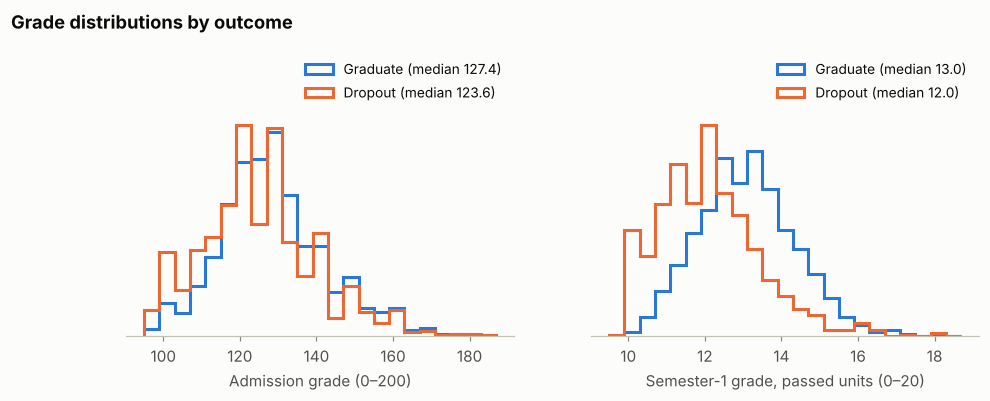

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
panels = [(df, "admission_grade", "Admission grade (0–200)", np.arange(95, 191, 4)),
          (sem, "sem1_grade_real", "Semester-1 grade, passed units (0–20)", np.arange(9.5, 19, 0.4))]
for ax, (data, col, label, bins) in zip(axes, panels):
    for outcome in ["Graduate", "Dropout"]:
        vals = data.loc[data[config.TARGET] == outcome, col].dropna()
        ax.hist(vals, bins=bins, density=True, histtype="step", linewidth=2,
                color=OUTCOME_COLORS[outcome], label=f"{outcome} (median {vals.median():.1f})")
    ax.set_xlabel(label)
    ax.set_yticks([])
    ax.set_ylim(0, ax.get_ylim()[1] * 1.3)
    ax.grid(False)
    ax.spines["left"].set_visible(False)
    ax.legend(loc="upper right", fontsize=9)
fig.suptitle("Grade distributions by outcome", x=0.02, ha="left", fontweight="bold")
save(fig, "fig1_grades_by_outcome")

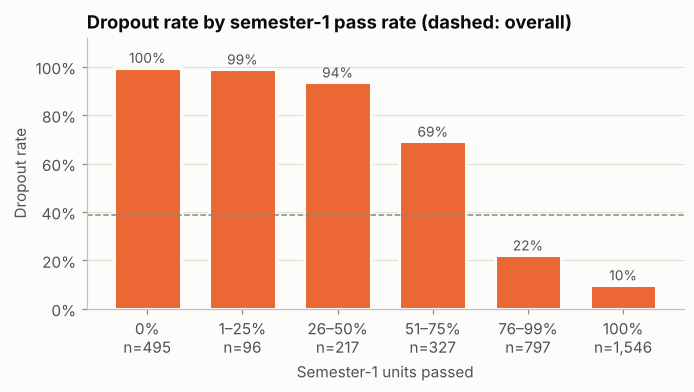

In [6]:
bins = [-0.01, 0, 0.25, 0.5, 0.75, 0.99, 1.0]
labels = ["0", "1–25", "26–50", "51–75", "76–99", "100"]
by_pr = sem_dropout.groupby(pd.cut(sem["sem1_pass_rate"], bins=bins, labels=labels), observed=True).agg(rate="mean", n="size")

fig, ax = plt.subplots(figsize=(7, 3.2))
ticks = [f"{l}%\nn={n:,}" for l, n in zip(by_pr.index, by_pr["n"])]
ax.bar(ticks, by_pr["rate"], color=OUTCOME_COLORS["Dropout"], width=0.7, edgecolor=SURFACE, linewidth=2)
for i, r in enumerate(by_pr["rate"]):
    ax.text(i, r + 0.02, f"{r:.0%}", ha="center", color=INK_SECONDARY, fontsize=9)
ax.axhline(sem_dropout.mean(), color=MUTED, linestyle="--", linewidth=1)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 1.12)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Semester-1 units passed")
ax.set_ylabel("Dropout rate")
ax.set_title("Dropout rate by semester-1 pass rate (dashed: overall)")
save(fig, "fig2_dropout_by_pass_rate")

Admission grade barely separates the outcomes; semester-1 grade and pass rate separate them clearly. This is consistent with the hypothesis that semester-1 data gives the largest gain.

## 4. Zeros in semester data
Data-quality check on all students.

In [7]:
cases = {
    "enrolled > 0, passed 0 (sem 1)": full["sem1_passed_none"] == 1,
    "all semester columns = 0": missing_records,
}
pd.DataFrame({k: y_all[m].value_counts().reindex(OUTCOME_ORDER).fillna(0).astype(int) for k, m in cases.items()}).T

target,Dropout,Enrolled,Graduate
"enrolled > 0, passed 0 (sem 1)",493,43,2
all semester columns = 0,77,28,75


In [8]:
print(full.loc[missing_records, "course"].value_counts().to_string())
print(f"course 171 total: {(full['course'] == 171).sum()}")

course
171    180
course 171 total: 215


- A recorded grade of 0 means no unit was passed; it is not an average. Grades are set to missing in that case (`sem*_grade_real`).
- 180 students have every semester column at 0 in both semesters, including credited units, yet 75 of them graduated. All 180 are in course 171 (Animation and Multimedia Design, 180 of its 215 students). These are missing records, not students who took no classes. They are kept at the enrollment stage and removed from the semester stages (`data.modeling_sample`).

## 5. Trajectory features
`_vs_entry`: semester grade − admission grade / 10. `_change_s1_s2`: semester 2 − semester 1.

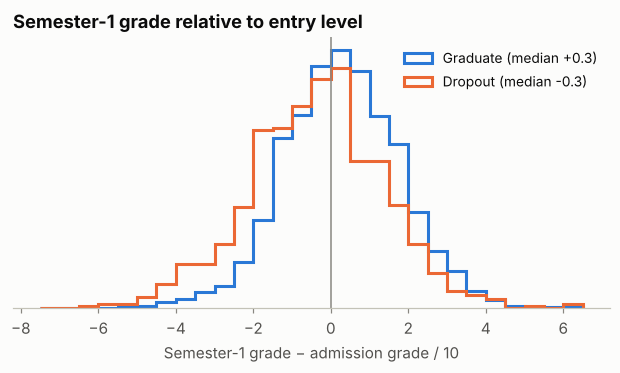

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for outcome in ["Graduate", "Dropout"]:
    vals = sem.loc[sem[config.TARGET] == outcome, "sem1_grade_vs_entry"].dropna()
    ax.hist(vals, bins=np.arange(-7.5, 6.6, 0.5), density=True, histtype="step", linewidth=2,
            color=OUTCOME_COLORS[outcome], label=f"{outcome} (median {vals.median():+.1f})")
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Semester-1 grade − admission grade / 10")
ax.legend(fontsize=9)
ax.set_title("Semester-1 grade relative to entry level")
save(fig, "fig3_grade_vs_entry")

In [10]:
traj = ["sem1_pass_rate", "sem2_pass_rate", "pass_rate_change_s1_s2",
        "sem1_grade_vs_entry", "sem2_grade_vs_entry", "grade_change_s1_s2", "sem1_eval_rate"]
summary = sem.groupby(config.TARGET)[traj].agg(["mean", "median"]).T.unstack()
summary.round(2)

target                 Dropout        Graduate       
                          mean median     mean median
sem1_pass_rate            0.41   0.40     0.93   1.00
sem2_pass_rate            0.31   0.17     0.93   1.00
pass_rate_change_s1_s2   -0.10   0.00    -0.00   0.00
sem1_grade_vs_entry      -0.41  -0.32     0.26   0.26
sem2_grade_vs_entry      -0.44  -0.50     0.31   0.29
grade_change_s1_s2       -0.08   0.00     0.04   0.00
sem1_eval_rate            1.35   1.33     1.25   1.17

In [11]:
change = sem["grade_change_s1_s2"].dropna()
print(f"grade_change_s1_s2 defined for {len(change):,} students (passed units in both semesters)")
print(f"  up by > 1 point: {(change > 1).sum()}, down by > 1 point: {(change < -1).sum()}, unchanged: {(change == 0).sum()}")

grade_change_s1_s2 defined for 2,802 students (passed units in both semesters)
  up by > 1 point: 404, down by > 1 point: 383, unchanged: 415


- Dropouts sit below their entry level in both semesters; graduates sit slightly above it.
- Pass rate falls from semester 1 to 2 for dropouts on average and stays flat for graduates.
- `grade_change_s1_s2` has a median of 0 because increases and decreases balance out in every group. It is also undefined for students who passed nothing in a semester, which is where the sharpest declines are, so `pass_rate_change_s1_s2` captures decline better.
- `eval_rate` counts exam attempts per enrolled unit, including retakes, so it can exceed 1. It is not an attendance measure and differs little by outcome.

## 6. Still-passing subgroup

In [12]:
passed_all = sem["sem1_passed_all"] == 1
sub = sem.loc[passed_all, config.TARGET].value_counts()
print(f"Passed every semester-1 unit: {passed_all.sum():,} students")
print(sub.to_string())
print(f"Dropout rate in subgroup: {sub['Dropout'] / sub.sum():.1%}  "
      f"({sub['Dropout'] / sem_dropout.sum():.1%} of dropouts with semester records)")

Passed every semester-1 unit: 1,546 students
target
Graduate    1395
Dropout      151
Dropout rate in subgroup: 9.8%  (11.2% of dropouts with semester records)


151 dropouts passed every semester-1 unit: 9.8% of this group and 11% of all dropouts with semester records. Their grades look normal by construction, so this is the hardest test for the models.

## Decisions for modeling

- **Label:** Dropout vs. Graduate; class weights for imbalance; report recall and PR-AUC.
- **Sample:** semester stages exclude the 180 students with missing semester records.
- **Enrollment stage:** reported with and without tuition and debtor status.
- **Features:** the `features.py` trajectory set; zero grades are treated as missing.
- **Subgroup:** report recall separately for still-passing dropouts.